In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


def load_dataset(filename):
    target_path = Path("./data") / f"{filename}.csv"

    if not target_path.is_file():
        raise FileNotFoundError(
            f"파일을 찾을 수 없습니다: {target_path.resolve()}"
        )

    # UTF-8 우선, 한글 Windows 인코딩 순서로 시도
    for encoding in ["utf-8-sig", "cp949", "euc-kr"]:
        try:
            return pd.read_csv(
                target_path,
                encoding=encoding,
                low_memory=False,
            )
        except UnicodeDecodeError:
            continue

    raise ValueError("파일 인코딩을 확인해 주세요.")


df = load_dataset("체류시간_찐최종")

display(df.head())

,선박명,총톤수,항만구분,터미널,선사,접안일시,출항일시,체류시간,순수물동량,Shift수량,...,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_유의파고_최댓값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,NORTHERN GENERAL,41835,신항,BNCT,CMA,2021-01-01 3:20,2021-01-01 19:00,15.666667,814,0,...,1.640,NaN,NaN,0.30,0.4,0.6,0.4,"5,000.00","5,000.00",0.0
1,PRESIDENT FD ROOSEVELT,75752,신항,BNCT,APL,2021-01-01 15:20,2021-01-03 0:00,32.666667,"1,589.00",260,...,1.850,NaN,NaN,0.30,0.4,0.6,0.4,"4,842.00","5,000.00",0.0
2,PRESIDENT CLEVELAND,75015,신항,BNCT,APL,2021-01-02 10:20,2021-01-03 0:05,13.750000,729,0,...,2.355,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
3,COSCO GUANGZHOU,109149,신항,BNCT,COS,2021-01-01 21:25,2021-01-03 5:30,32.083333,"2,153.00",0,...,2.050,NaN,NaN,0.25,0.3,0.5,0.4,"4,842.00","5,000.00",0.0
4,CONTSHIP DAY,7170,신항,BNCT,APC,2021-01-03 9:15,2021-01-03 17:50,8.583333,222,0,...,2.830,NaN,NaN,0.30,0.3,0.5,0.4,"5,000.00","5,000.00",0.0


In [11]:
df.columns.tolist()

['선박명',
 '총톤수',
 '항만구분',
 '터미널',
 '선사',
 '접안일시',
 '출항일시',
 '체류시간',
 '순수물동량',
 'Shift수량',
 '총작업량',
 '체류시간_풍속_중앙값_mps',
 '체류시간_최대순간풍속_최댓값_mps',
 '체류시간_최대순간풍속_중앙값_mps',
 '체류시간_유의파고_중앙값_m',
 '체류시간_유의파고_최댓값_m',
 '체류시간_순간최대파고_최댓값_m',
 '체류시간_순간최대파고_중앙값_m',
 '체류시간_시정_최솟값_10m',
 '체류시간_시정_중앙값_10m',
 '체류시간_특보노출시간(h)']

In [12]:
# 원본 복사
df= df.copy()

#결측치 삭제
df = df.dropna()

In [13]:
# 새 열 생성: 0시간이면 0, 0시간 초과면 1
df["특보유무"] = (
    df["체류시간_특보노출시간(h)"] > 0
).astype("Int64")

# 원래 값이 결측이면 새 열도 결측으로 유지
df.loc[df["체류시간_특보노출시간(h)"].isna(), "특보유무"] = pd.NA

# 결과 확인
display(df[["체류시간_특보노출시간(h)", "특보유무"]].head(10))

,체류시간_특보노출시간(h),특보유무
77,0.0,0
78,0.0,0
79,0.0,0
80,0.0,0
81,0.0,0
82,0.0,0
83,0.0,0
84,0.0,0
85,13.0,1
86,13.0,1


In [14]:
df.isna().sum()

선박명                    0
총톤수                    0
항만구분                   0
터미널                    0
선사                     0
접안일시                   0
출항일시                   0
체류시간                   0
순수물동량                  0
Shift수량                0
총작업량                   0
체류시간_풍속_중앙값_mps        0
체류시간_최대순간풍속_최댓값_mps    0
체류시간_최대순간풍속_중앙값_mps    0
체류시간_유의파고_중앙값_m        0
체류시간_유의파고_최댓값_m        0
체류시간_순간최대파고_최댓값_m      0
체류시간_순간최대파고_중앙값_m      0
체류시간_시정_최솟값_10m        0
체류시간_시정_중앙값_10m        0
체류시간_특보노출시간(h)         0
특보유무                   0
dtype: int64

In [15]:
# 항만 이름 앞뒤 공백 제거
df["항만구분"] = df["항만구분"].str.strip()

# 북항을 기준으로 신항 더미 생성
df["신항더미"] = df["항만구분"].map({
    "북항": 0,
    "신항": 1,
})

# 결측값이나 예상하지 못한 항만 이름 확인
if df["신항더미"].isna().any():
    raise ValueError("항만구분에 결측값 또는 신항·북항 이외의 값이 있습니다.")

df["신항더미"] = df["신항더미"].astype(int)


# 선형성 점검

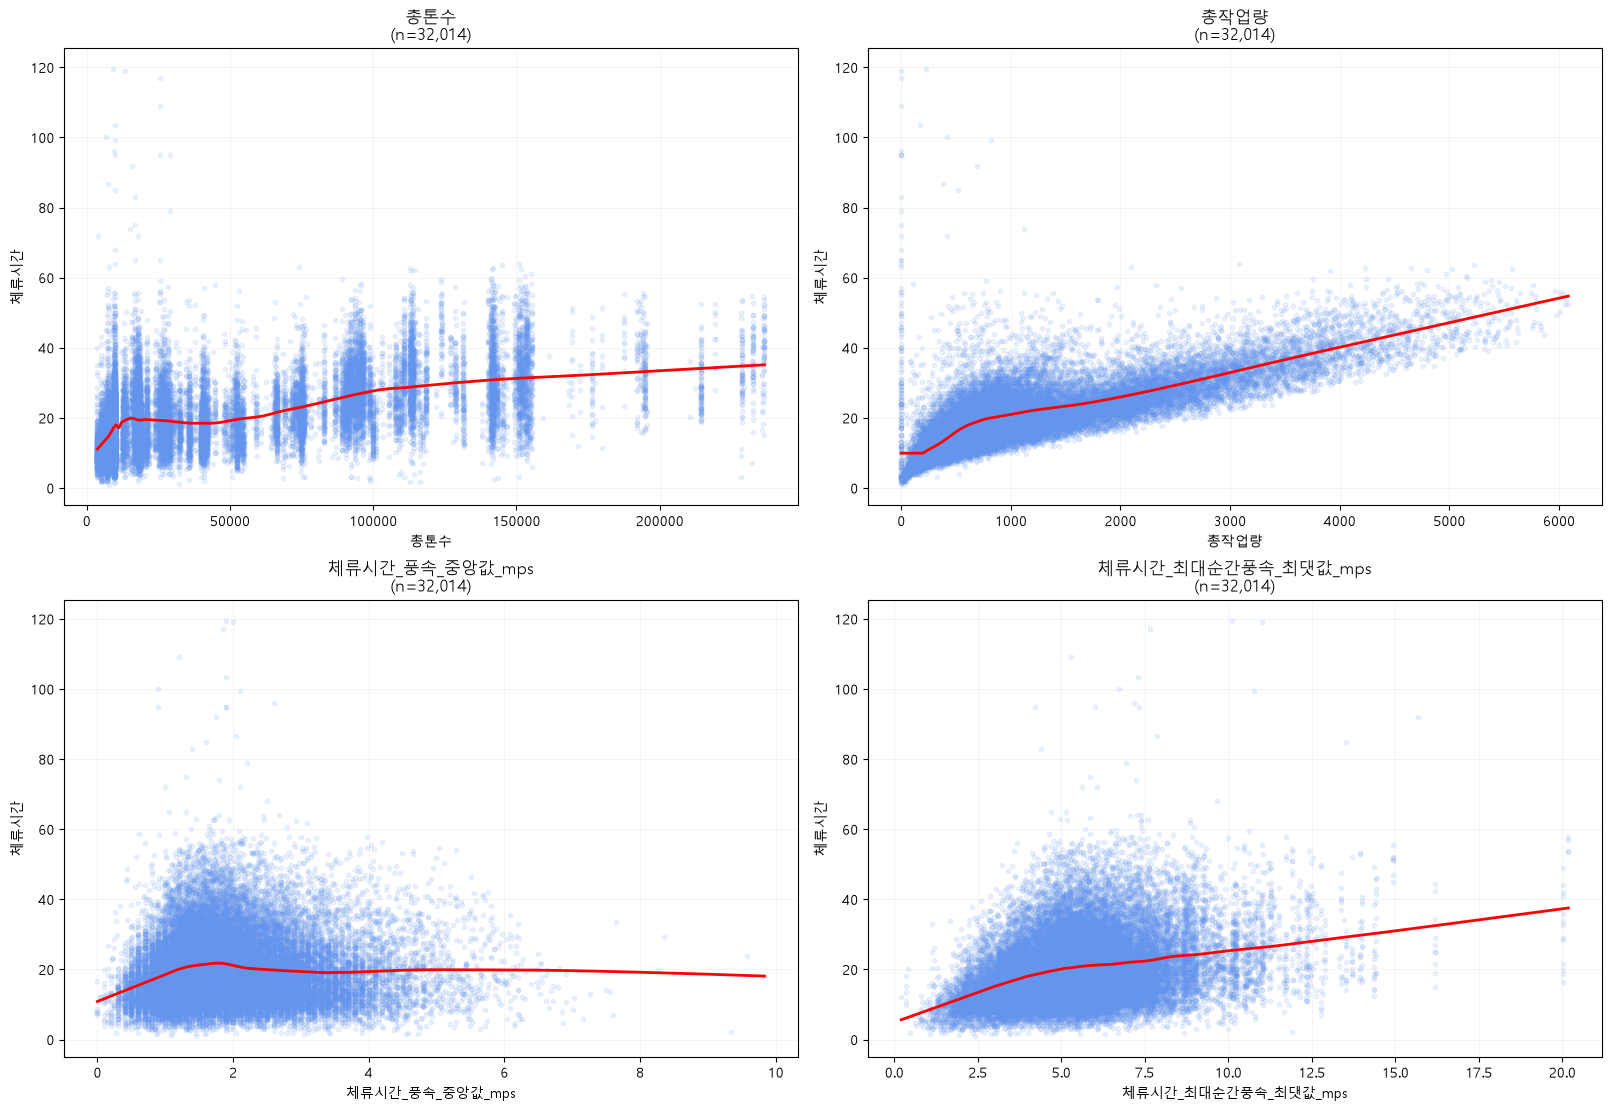

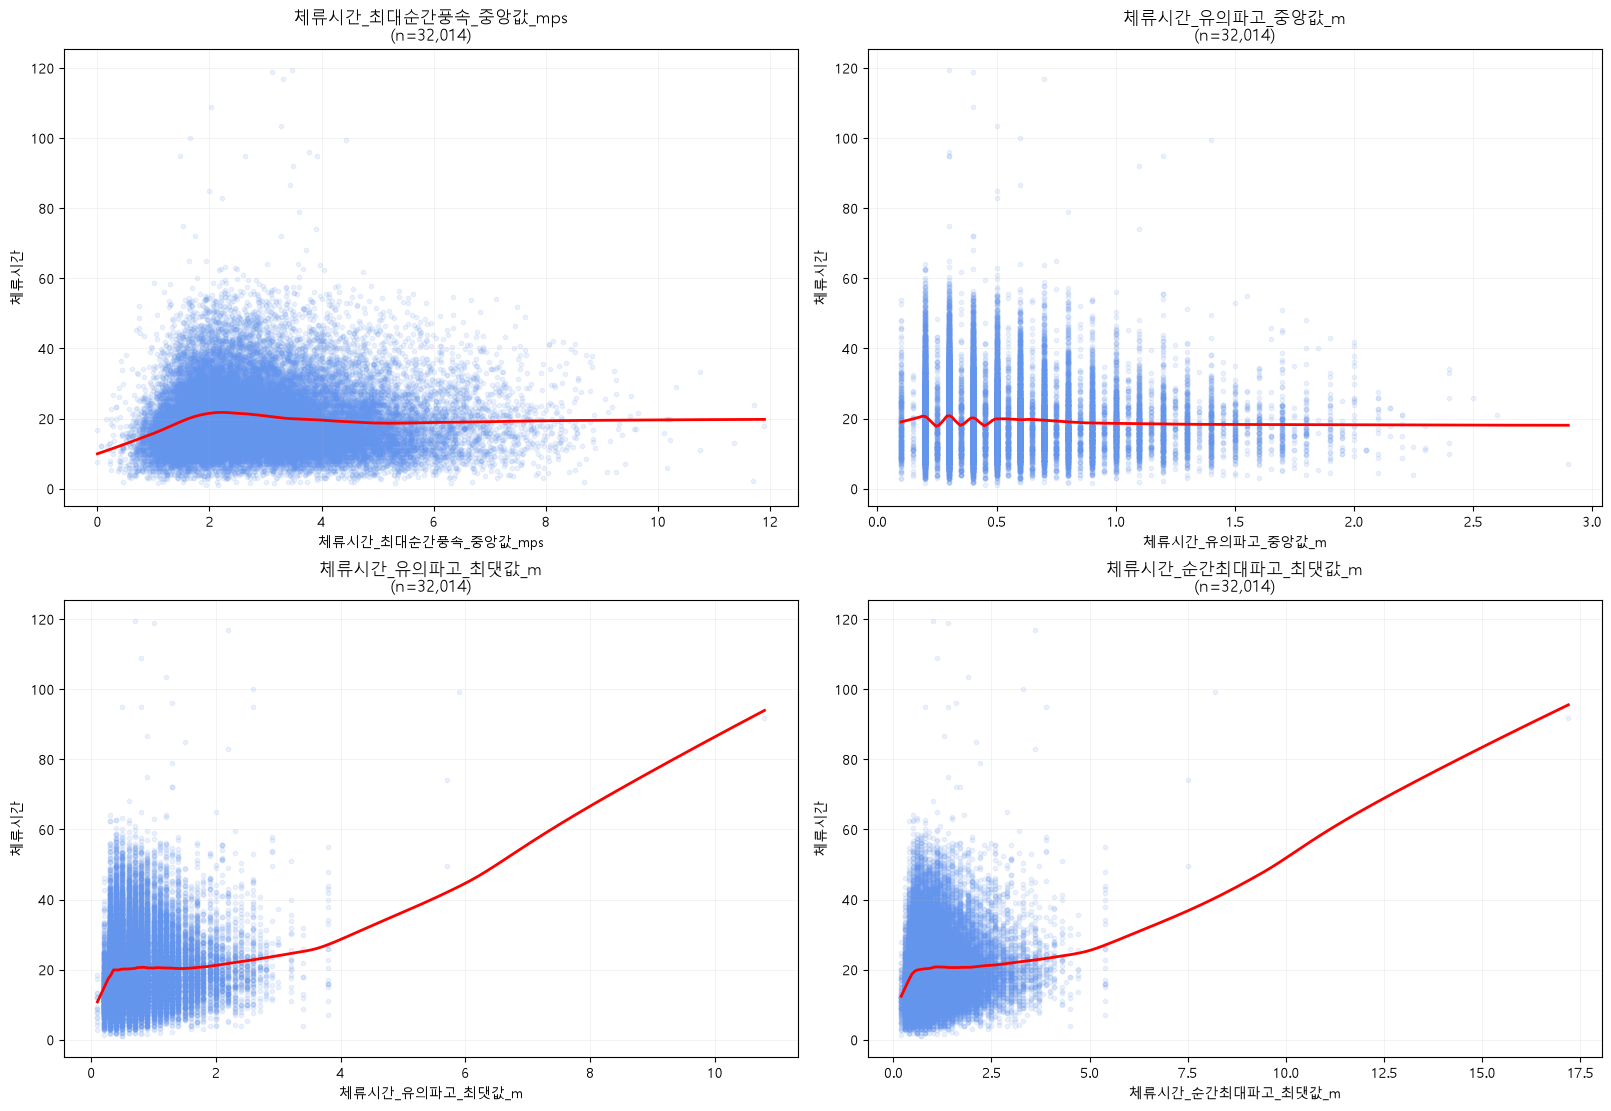

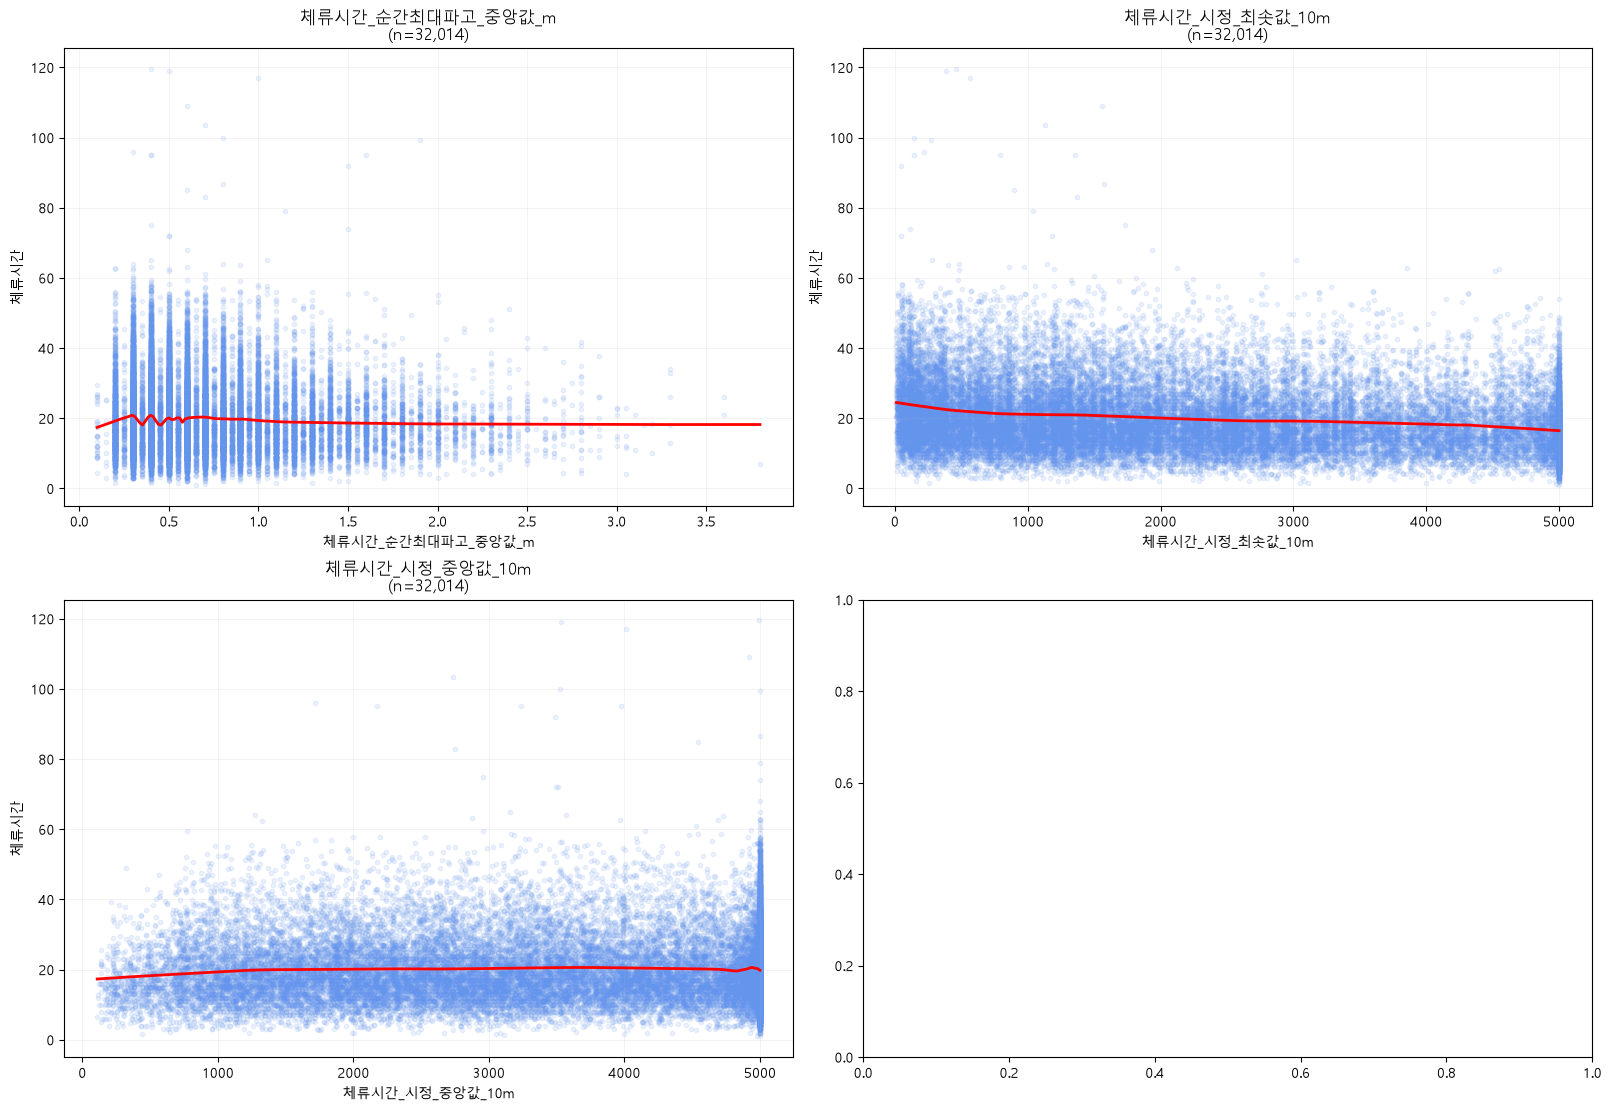

In [16]:
# 종속변수
y_col = "체류시간"

# 독립변수
x_cols = [
    "총톤수",
    "총작업량",
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]


# 쉼표를 제거하고 숫자로 변환
def 숫자변환(열):
    return pd.to_numeric(
        열.astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    ).to_numpy(dtype=float, na_value=np.nan)


# 가까운 관측값으로 빨간 곡선 계산
def 추세선(x, y):
    위치 = np.linspace(x.min(), x.max(), 250)
    결과 = []
    개수 = min(len(x), max(2, int(np.ceil(len(x) * 0.25))))

    for 기준 in 위치:
        거리 = np.abs(x - 기준)
        범위 = np.partition(거리, 개수 - 1)[개수 - 1]

        # 같은 X값이 몰려 있으면 평균 사용
        if 범위 == 0:
            결과.append(y[거리 == 0].mean())
            continue

        선택 = 거리 < 범위
        주변x = (x[선택] - 기준) / 범위
        주변y = y[선택]
        가중치 = (1 - np.abs(주변x) ** 3) ** 3

        if 가중치.sum() == 0:
            값 = y[거리 == 거리.min()].mean()
        elif np.ptp(주변x) < 1e-12:
            값 = np.average(주변y, weights=가중치)
        else:
            # 가까운 점에 더 큰 가중치를 주어 짧은 직선 계산
            A = np.column_stack([np.ones(len(주변x)), 주변x])
            w = np.sqrt(가중치)

            계수 = np.linalg.lstsq(
                A * w[:, None],
                주변y * w,
                rcond=1e-12,
            )[0]
            값 = 계수[0]

        결과.append(값)

    return 위치, np.array(결과)


체류시간 = 숫자변환(df[y_col])

# 그래프를 4개씩 출력
for 시작 in range(0, len(x_cols), 4):
    fig, axes = plt.subplots(
        2, 2, figsize=(16, 11), layout="constrained"
    )

    for ax, 변수 in zip(axes.flat, x_cols[시작:시작 + 4]):
        독립변수 = 숫자변환(df[변수])

        # X와 Y가 모두 정상적인 숫자인 행만 사용
        사용 = np.isfinite(독립변수) & np.isfinite(체류시간)
        x = 독립변수[사용]
        y = 체류시간[사용]

        # 실제 관측값
        ax.scatter(x, y, s=10, alpha=0.12, color="cornflowerblue")

        # 빨간 곡선
        if len(x) >= 3 and np.unique(x).size > 1:
            선x, 선y = 추세선(x, y)
            ax.plot(선x, 선y, color="red", linewidth=2)

        ax.set_title(f"{변수}\n(n={len(x):,})")
        ax.set_xlabel(변수)
        ax.set_ylabel(y_col)
        ax.grid(alpha=0.2)

    plt.show()

# 다중공선성 확인

In [17]:

import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

# 기존 독립변수 + 항만구분 더미
x_cols = [
    "총톤수",
    "총작업량",
    "신항더미",  # 북항=0, 신항=1
    "특보유무", # 0=없음, 1=있음
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]

# 분석할 변수 선택
# 쉼표를 제거하고 실제 숫자형으로 저장
for col in x_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="raise",
    )

X_vif = df[x_cols].astype(float)

# 상수항 추가
X_const = sm.add_constant(X_vif, has_constant="add")
values = X_const.to_numpy(dtype=float)

# 상수항을 제외한 각 변수의 VIF 계산
vif_result = pd.DataFrame({
    "독립변수": x_cols,
    "VIF": [
        variance_inflation_factor(values, i + 1)
        for i in range(len(x_cols))
    ],
})

# 높은 순서로 정렬
vif_result = vif_result.sort_values("VIF", ascending=False)

print(f"VIF 계산 표본 수: {len(X_vif):,}")
display(
    vif_result.style
    .format({"VIF": "{:.3f}"})
    .hide(axis="index")
)


VIF 계산 표본 수: 32,014


독립변수,VIF
체류시간_순간최대파고_중앙값_m,47.047
체류시간_유의파고_중앙값_m,45.767
체류시간_유의파고_최댓값_m,23.552
체류시간_순간최대파고_최댓값_m,20.469
체류시간_최대순간풍속_중앙값_mps,10.221
체류시간_풍속_중앙값_mps,9.177
총톤수,3.369
총작업량,3.181
체류시간_최대순간풍속_최댓값_mps,2.544
체류시간_시정_최솟값_10m,2.492


# 다중공선선 제거 (VIF > 10)

In [18]:

threshold = 10

X_vif = df[x_cols]

selected_vars = x_cols.copy()
removed = []
step = 1

print(f"분석 표본 수: {len(X_vif):,}")

while True:
    # 남아 있는 변수에 상수항 추가
    X_const = sm.add_constant(
        X_vif[selected_vars],
        has_constant="add",
    )
    values = X_const.to_numpy()

    # 현재 변수들의 VIF 계산
    vif_result = pd.DataFrame({
        "독립변수": selected_vars,
        "VIF": [
            variance_inflation_factor(values, i + 1)
            for i in range(len(selected_vars))
        ],
    }).sort_values("VIF", ascending=False)

    if vif_result["VIF"].isna().any():
        raise ValueError("VIF 계산에 문제가 있습니다. 일정한 값의 변수가 있는지 확인하세요.")

    print(f"\n{step}단계")
    display(
        vif_result.style
        .format({"VIF": "{:.3f}"})
        .hide(axis="index")
    )

    # VIF가 가장 높은 변수 확인
    max_var = vif_result.iloc[0]["독립변수"]
    max_vif = vif_result.iloc[0]["VIF"]

    # 모두 기준 이하면 종료
    if max_vif <= threshold:
        print(f"모든 VIF가 {threshold} 이하이므로 종료합니다.")
        break

    # 가장 높은 변수 하나 제거
    print(f"제거: {max_var} / VIF: {max_vif:.3f}")
    removed.append([step, max_var, max_vif])
    selected_vars.remove(max_var)
    step += 1

# 최종 결과 저장
final_vif = vif_result.copy()
X_final = X_vif[selected_vars].copy()

removal_history = pd.DataFrame(
    removed,
    columns=["제거 순서", "제거 변수", "제거 당시 VIF"],
)

print("\n제거 이력")
display(
    removal_history.style
    .format({"제거 당시 VIF": "{:.3f}"})
    .hide(axis="index")
)

print("\n최종 선택 변수")
display(pd.DataFrame({"독립변수": selected_vars}))


분석 표본 수: 32,014

1단계


독립변수,VIF
체류시간_순간최대파고_중앙값_m,47.047
체류시간_유의파고_중앙값_m,45.767
체류시간_유의파고_최댓값_m,23.552
체류시간_순간최대파고_최댓값_m,20.469
체류시간_최대순간풍속_중앙값_mps,10.221
체류시간_풍속_중앙값_mps,9.177
총톤수,3.369
총작업량,3.181
체류시간_최대순간풍속_최댓값_mps,2.544
체류시간_시정_최솟값_10m,2.492


제거: 체류시간_순간최대파고_중앙값_m / VIF: 47.047

2단계


독립변수,VIF
체류시간_유의파고_최댓값_m,22.674
체류시간_순간최대파고_최댓값_m,18.602
체류시간_최대순간풍속_중앙값_mps,10.204
체류시간_풍속_중앙값_mps,9.171
체류시간_유의파고_중앙값_m,5.275
총톤수,3.368
총작업량,3.174
체류시간_최대순간풍속_최댓값_mps,2.543
체류시간_시정_최솟값_10m,2.486
체류시간_시정_중앙값_10m,2.393


제거: 체류시간_유의파고_최댓값_m / VIF: 22.674

3단계


독립변수,VIF
체류시간_최대순간풍속_중앙값_mps,10.180
체류시간_풍속_중앙값_mps,9.171
체류시간_유의파고_중앙값_m,4.533
체류시간_순간최대파고_최댓값_m,4.195
총톤수,3.368
총작업량,3.174
체류시간_최대순간풍속_최댓값_mps,2.524
체류시간_시정_최솟값_10m,2.471
체류시간_시정_중앙값_10m,2.392
신항더미,2.095


... (2 outputs left out)

모든 VIF가 10 이하이므로 종료합니다.

제거 이력


제거 순서,제거 변수,제거 당시 VIF
1,체류시간_순간최대파고_중앙값_m,47.047
2,체류시간_유의파고_최댓값_m,22.674
3,체류시간_최대순간풍속_중앙값_mps,10.180



최종 선택 변수


,독립변수
0,총톤수
1,총작업량
2,신항더미
3,특보유무
4,체류시간_풍속_중앙값_mps
5,체류시간_최대순간풍속_최댓값_mps
6,체류시간_유의파고_중앙값_m
7,체류시간_순간최대파고_최댓값_m
8,체류시간_시정_최솟값_10m
9,체류시간_시정_중앙값_10m


신항/북항 별 VIF 비교

In [21]:
import pandas as pd
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

# 1. 비교할 변수: 기본 변수 3개 + 기존 기상변수 9개
vif_vars = [
    "총톤수",
    "총작업량",
    "특보유무",
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_유의파고_최댓값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]

threshold = 10

# 현재 df는 앞에서 숫자형 정리와 결측치 삭제를 완료한 자료 사용
# 원본 df를 변경하지 않고 항만별 계산 자료만 생성
port_data = {
    port: df.loc[
        df["항만구분"] == port,
        vif_vars,
    ].astype(float).copy()
    for port in ["북항", "신항"]
}


# 2. VIF 계산 함수
def calculate_vif(X):
    if X.empty:
        raise ValueError("VIF를 계산할 관측값이 없습니다.")

    constant_vars = X.columns[X.nunique() <= 1].tolist()

    if constant_vars:
        raise ValueError(
            f"값이 일정해서 VIF를 계산할 수 없는 변수: {constant_vars}"
        )

    # 변수 하나만 남으면 다른 설명변수에 의한 공선성은 없음
    if X.shape[1] == 1:
        return pd.Series(
            [1.0],
            index=X.columns,
            name="VIF",
        )

    X_const = sm.add_constant(X, has_constant="add")
    values = X_const.to_numpy(dtype=float)

    result = pd.Series(
        [
            variance_inflation_factor(values, i + 1)
            for i in range(X.shape[1])
        ],
        index=X.columns,
        name="VIF",
    )

    if result.isna().any():
        raise ValueError("VIF에 NaN이 발생했습니다. 자료를 확인하세요.")

    return result


# 3. 항만별 최초 VIF 비교
initial_vif = pd.DataFrame({
    port: calculate_vif(X)
    for port, X in port_data.items()
})

initial_vif.index.name = "독립변수"

# 두 항만 중 더 높은 VIF를 기준으로 표 정렬
initial_vif = initial_vif.loc[
    initial_vif.max(axis=1)
    .sort_values(ascending=False)
    .index
]

print("항만별 계산 표본 수")
display(
    pd.DataFrame({
        "항만": list(port_data),
        "표본 수": [len(X) for X in port_data.values()],
    }).style
    .format({"표본 수": "{:,.0f}"})
    .hide(axis="index")
)

print("\n신항·북항 최초 VIF 비교")
display(
    initial_vif.style
    .format("{:.3f}")
    .map(
        lambda v: "background-color: #ffe0e0"
        if v > threshold else ""
    )
)

# 4. 항만별 삭제 순서 모의 계산
# 원본 df와 실제 모형의 변수 목록은 변경하지 않음
simulation_records = []
remaining_by_port = {}
final_vif_by_port = {}

for port, X in port_data.items():
    remaining = vif_vars.copy()
    step = 1

    while True:
        current_vif = calculate_vif(X[remaining])

        # 동률이면 기존 변수 목록 순서를 유지
        current_vif = current_vif.sort_values(
            ascending=False,
            kind="stable",
        )

        highest_var = current_vif.index[0]
        highest_vif = current_vif.iloc[0]

        # 남은 모든 변수의 VIF가 10 이하면 종료
        if highest_vif <= threshold:
            break

        simulation_records.append({
            "항만": port,
            "삭제 순서": step,
            "삭제 예상 변수": highest_var,
            "삭제 직전 VIF": highest_vif,
        })

        # 모의 계산용 목록에서만 제외
        remaining.remove(highest_var)
        step += 1

    remaining_by_port[port] = remaining.copy()
    final_vif_by_port[port] = current_vif.copy()

# 5. 삭제 예상 순서를 한 표에서 비교
history = pd.DataFrame(
    simulation_records,
    columns=[
        "항만",
        "삭제 순서",
        "삭제 예상 변수",
        "삭제 직전 VIF",
    ],
)

print(f"\n삭제 순서 모의 계산: 가장 높은 VIF가 {threshold} 초과일 때 제외")

if history.empty:
    print("두 항만 모두 삭제 대상이 없습니다.")

else:
    history_tables = []

    for port in ["북항", "신항"]:
        part = (
            history.loc[
                history["항만"] == port,
                ["삭제 순서", "삭제 예상 변수", "삭제 직전 VIF"],
            ]
            .set_index("삭제 순서")
            .rename(columns={
                "삭제 예상 변수": f"{port} 삭제 예상 변수",
                "삭제 직전 VIF": f"{port} 삭제 직전 VIF",
            })
        )

        history_tables.append(part)

    removal_comparison = pd.concat(
        history_tables,
        axis=1,
    ).sort_index()

    display(
        removal_comparison.style.format(
            {
                "북항 삭제 직전 VIF": "{:.3f}",
                "신항 삭제 직전 VIF": "{:.3f}",
            },
            na_rep="—",
        )
    )

# 6. 모의 삭제 후 남는 변수와 VIF 비교
final_comparison = pd.DataFrame({
    port: final_vif_by_port[port].reindex(vif_vars)
    for port in ["북항", "신항"]
})

final_comparison.index.name = "독립변수"

print("\n모의 삭제 후 VIF 비교: '제외'는 모의 계산에서 제외된 변수")
display(
    final_comparison.style.format(
        "{:.3f}",
        na_rep="제외",
    )
)

print("\n※ 위 삭제는 모의 계산입니다. 원본 df와 회귀모형은 변경하지 않았습니다.")

항만별 계산 표본 수


항만,표본 수
북항,"16,404"
신항,"15,610"



신항·북항 최초 VIF 비교


,북항,신항
독립변수,,
체류시간_순간최대파고_중앙값_m,62.773,23.028
체류시간_유의파고_중앙값_m,60.231,21.596
체류시간_유의파고_최댓값_m,30.408,13.171
체류시간_순간최대파고_최댓값_m,28.796,10.670
체류시간_최대순간풍속_중앙값_mps,7.418,22.445
체류시간_풍속_중앙값_mps,6.208,20.865
체류시간_최대순간풍속_최댓값_mps,2.885,2.423
체류시간_시정_최솟값_10m,2.581,2.435
체류시간_시정_중앙값_10m,2.509,2.315



삭제 순서 모의 계산: 가장 높은 VIF가 10 초과일 때 제외


,북항 삭제 예상 변수,북항 삭제 직전 VIF,신항 삭제 예상 변수,신항 삭제 직전 VIF
삭제 순서,,,,
1,체류시간_순간최대파고_중앙값_m,62.773,체류시간_순간최대파고_중앙값_m,23.028
2,체류시간_유의파고_최댓값_m,28.783,체류시간_최대순간풍속_중앙값_mps,22.146
3,—,—,체류시간_유의파고_최댓값_m,12.896



모의 삭제 후 VIF 비교: '제외'는 모의 계산에서 제외된 변수


,북항,신항
독립변수,,
총톤수,1.358,2.046
총작업량,1.548,2.343
특보유무,1.703,1.594
체류시간_풍속_중앙값_mps,6.207,2.155
체류시간_최대순간풍속_최댓값_mps,2.878,2.357
체류시간_최대순간풍속_중앙값_mps,7.413,제외
체류시간_유의파고_중앙값_m,4.664,3.089
체류시간_유의파고_최댓값_m,제외,제외
체류시간_순간최대파고_최댓값_m,4.551,3.080



※ 위 삭제는 모의 계산입니다. 원본 df와 회귀모형은 변경하지 않았습니다.


In [19]:
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

# 1. 사용할 기상변수: 기존 모형과 동일한 6개
weather_vars = [
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]

# 상호작용을 만들 변수
interaction_vars = [
                       "총톤수",
                       "총작업량",
                       "특보유무",
                   ] + weather_vars

# 2. 네 모형에서 같은 분석자료 사용
# float 지정은 특보유무의 Int64 자료형을 OLS에 넣기 위한 것
data = df[
    ["체류시간", "신항더미"] + interaction_vars
    ].astype(float).copy()

y = data["체류시간"]

# 3. 신항더미와 각 변수의 상호작용항 생성
for col in interaction_vars:
    data[f"신항더미 × {col}"] = data["신항더미"] * data[col]

# 4. 단계별 독립변수 설정

# 모형 1: 항만구분
vars_1 = ["신항더미"]

# 모형 2: 총톤수·총작업량과 각각의 상호작용 추가
vars_2 = vars_1 + [
    "총톤수",
    "총작업량",
    "신항더미 × 총톤수",
    "신항더미 × 총작업량",
]

# 모형 3: 특보유무와 상호작용 추가
vars_3 = vars_2 + [
    "특보유무",
    "신항더미 × 특보유무",
]

# 모형 4: 기상변수 6개와 각각의 상호작용 추가
vars_4 = (
        vars_3
        + weather_vars
        + [f"신항더미 × {col}" for col in weather_vars]
)

# 5. 절편을 포함한 OLS 모형 적합
X_1 = sm.add_constant(data[vars_1], has_constant="add")
X_2 = sm.add_constant(data[vars_2], has_constant="add")
X_3 = sm.add_constant(data[vars_3], has_constant="add")
X_4 = sm.add_constant(data[vars_4], has_constant="add")

model_1 = sm.OLS(y, X_1).fit()
model_2 = sm.OLS(y, X_2).fit()
model_3 = sm.OLS(y, X_3).fit()
model_4 = sm.OLS(y, X_4).fit()

# 6. 모형 설명력 비교
models = [model_1, model_2, model_3, model_4]

model_names = [
    "모형 1: 항만구분",
    "모형 2: 총톤수·총작업량 및 상호작용 추가",
    "모형 3: 특보유무 및 상호작용 추가",
    "모형 4: 기상변수 및 상호작용 추가",
]

comparison = pd.DataFrame({
    "모형": model_names,
    "표본 수": [int(model.nobs) for model in models],
    "독립변수 수": [
        len(vars_1),
        len(vars_2),
        len(vars_3),
        len(vars_4),
    ],
    "R²": [model.rsquared for model in models],
    "수정 R²": [model.rsquared_adj for model in models],
    "이전 모형 대비 R² 증가": [
        0,
        model_2.rsquared - model_1.rsquared,
        model_3.rsquared - model_2.rsquared,
        model_4.rsquared - model_3.rsquared,
    ],
})

print("모형 비교")
display(
    comparison.style
    .format({
        "표본 수": "{:,.0f}",
        "독립변수 수": "{:.0f}",
        "R²": "{:.4f}",
        "수정 R²": "{:.4f}",
        "이전 모형 대비 R² 증가": "{:.4f}",
    })
    .hide(axis="index")
)

# 7. 각 모형의 회귀계수·표준오차·신뢰구간·p값
for name, model in zip(model_names, models):
    ci = model.conf_int()

    result = pd.DataFrame({
        "회귀계수": model.params,
        "표준오차": model.bse,
        "95% CI 하한": ci[0],
        "95% CI 상한": ci[1],
        "p값": model.pvalues,
    }).rename(index={"const": "절편"})

    print(f"\n{name}")
    display(
        result.style.format({
            "회귀계수": "{:.6g}",
            "표준오차": "{:.6g}",
            "95% CI 하한": "{:.6g}",
            "95% CI 상한": "{:.6g}",
            "p값": lambda p: "<0.001" if p < 0.001 else f"{p:.3f}",
        })
    )

모형 비교


모형,표본 수,독립변수 수,R²,수정 R²,이전 모형 대비 R² 증가
모형 1: 항만구분,"32,014",1,0.0624,0.0623,0.0000
모형 2: 총톤수·총작업량 및 상호작용 추가,"32,014",5,0.6858,0.6857,0.6234
모형 3: 특보유무 및 상호작용 추가,"32,014",7,0.6898,0.6897,0.0040
모형 4: 기상변수 및 상호작용 추가,"32,014",19,0.7309,0.7308,0.0411



모형 1: 항만구분


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
절편,17.7235,0.0715591,17.5832,17.8637,<0.001
신항더미,4.72869,0.102479,4.52783,4.92956,<0.001



모형 2: 총톤수·총작업량 및 상호작용 추가


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
절편,8.81436,0.0912442,8.63552,8.9932,<0.001
신항더미,0.347239,0.119997,0.112041,0.582437,0.004
총톤수,-7.5586e-05,6.0775e-06,-8.74981e-05,-6.36739e-05,<0.001
총작업량,0.0174375,0.000158627,0.0171265,0.0177484,<0.001
신항더미 × 총톤수,6.70638e-05,6.18908e-06,5.49329e-05,7.91946e-05,<0.001
신항더미 × 총작업량,-0.00917763,0.000166837,-0.00950463,-0.00885062,<0.001



모형 3: 특보유무 및 상호작용 추가


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
절편,8.58694,0.0915219,8.40756,8.76633,<0.001
신항더미,0.461336,0.120525,0.225102,0.69757,<0.001
총톤수,-7.56588e-05,6.03876e-06,-8.7495e-05,-6.38226e-05,<0.001
총작업량,0.0173331,0.00015772,0.017024,0.0176423,<0.001
신항더미 × 총톤수,6.72531e-05,6.14965e-06,5.51996e-05,7.93066e-05,<0.001
신항더미 × 총작업량,-0.00910596,0.000165911,-0.00943115,-0.00878077,<0.001
특보유무,2.2414,0.123318,1.99969,2.48311,<0.001
신항더미 × 특보유무,-1.14222,0.172205,-1.47975,-0.804692,<0.001



모형 4: 기상변수 및 상호작용 추가


,회귀계수,표준오차,95% CI 하한,95% CI 상한,p값
절편,6.0183,0.174608,5.67607,6.36054,<0.001
신항더미,1.7667,0.240205,1.29589,2.23752,<0.001
총톤수,-5.23464e-05,5.641e-06,-6.3403e-05,-4.12898e-05,<0.001
총작업량,0.0142306,0.000156533,0.0139238,0.0145374,<0.001
신항더미 × 총톤수,4.43268e-05,5.74414e-06,3.30681e-05,5.55855e-05,<0.001
신항더미 × 총작업량,-0.00664608,0.000164706,-0.00696891,-0.00632325,<0.001
특보유무,0.6684,0.149707,0.374969,0.961832,<0.001
신항더미 × 특보유무,-0.0368069,0.20552,-0.439633,0.366019,0.858
체류시간_풍속_중앙값_mps,-1.44942,0.0627765,-1.57246,-1.32637,<0.001
체류시간_최대순간풍속_최댓값_mps,1.15272,0.0337477,1.08657,1.21886,<0.001


### 잔차 검증


모형 4 진단 표본 수: 32,014


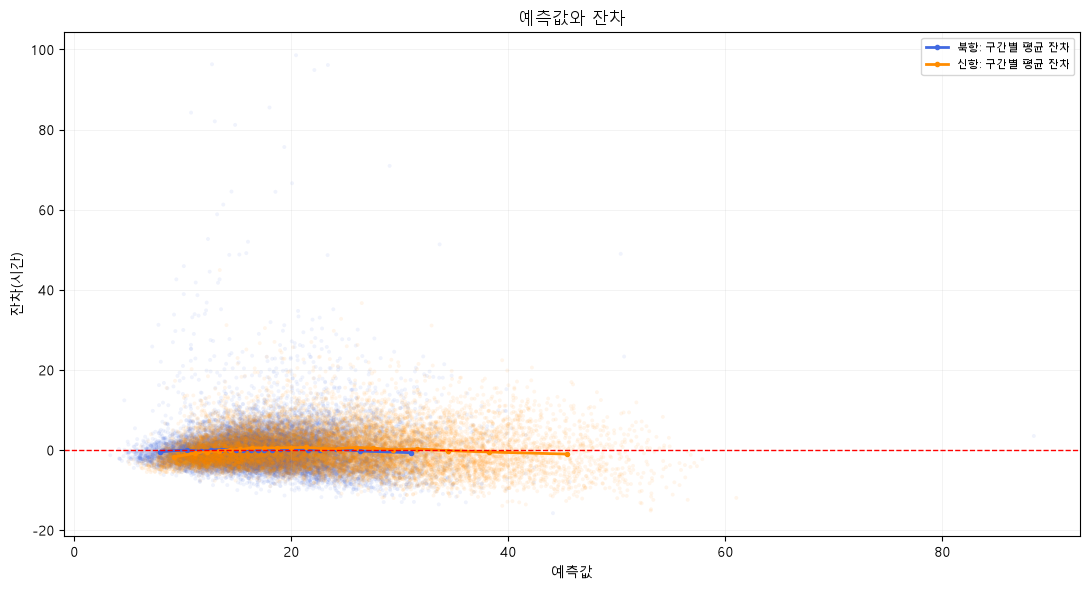

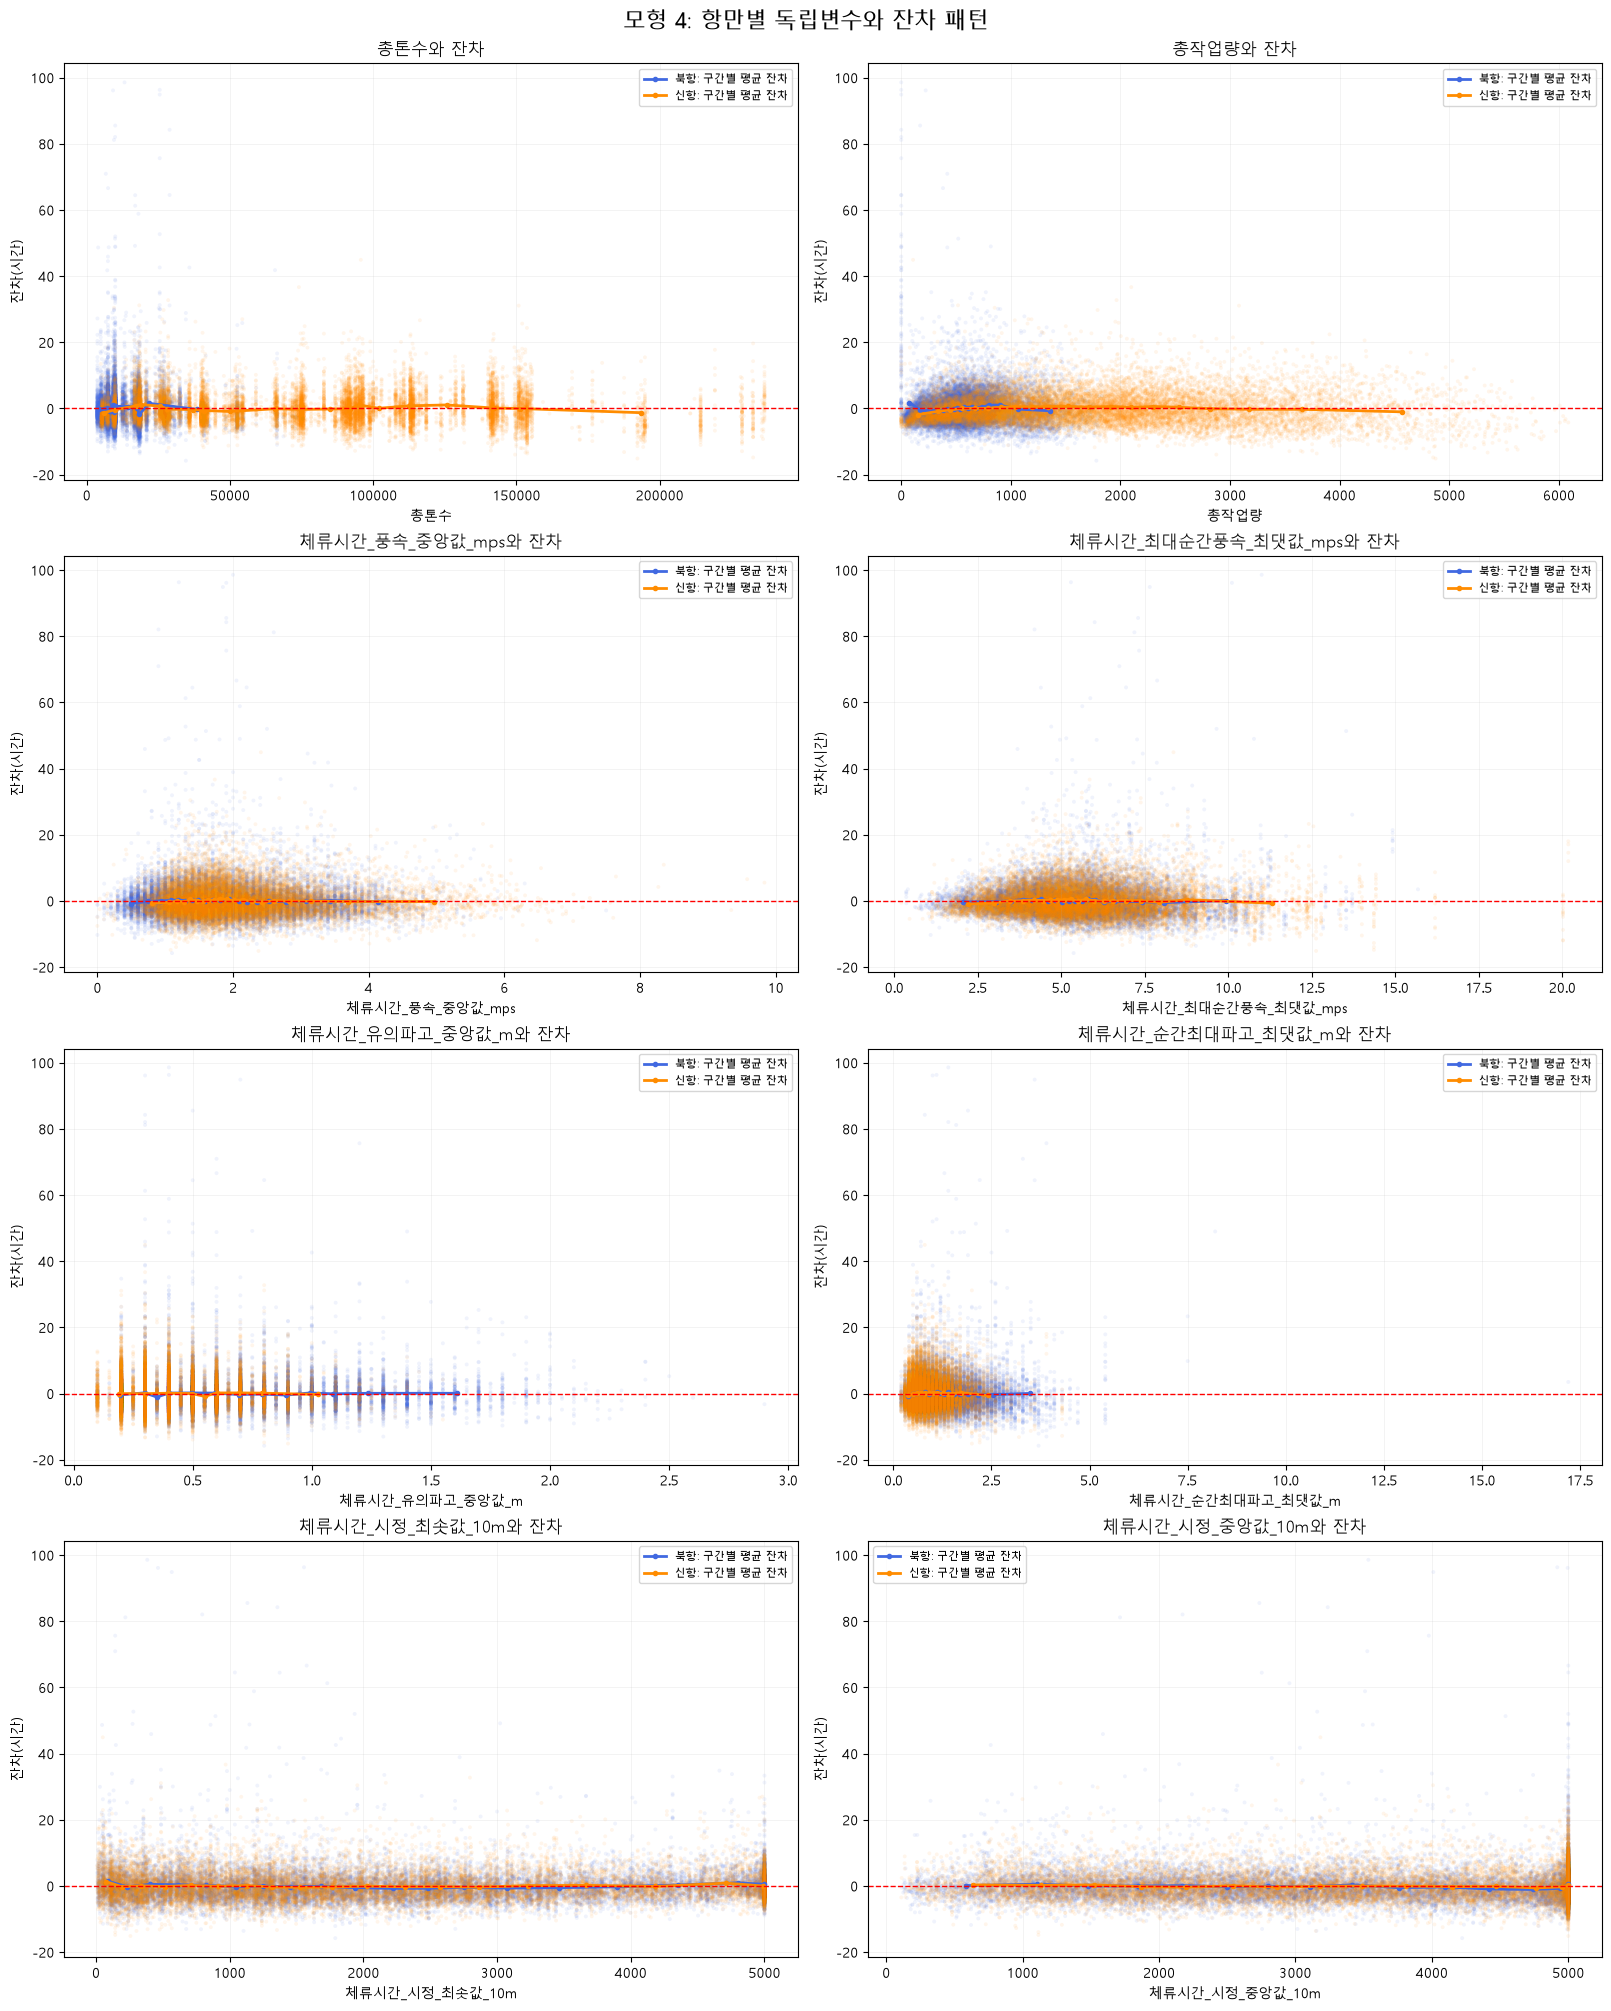

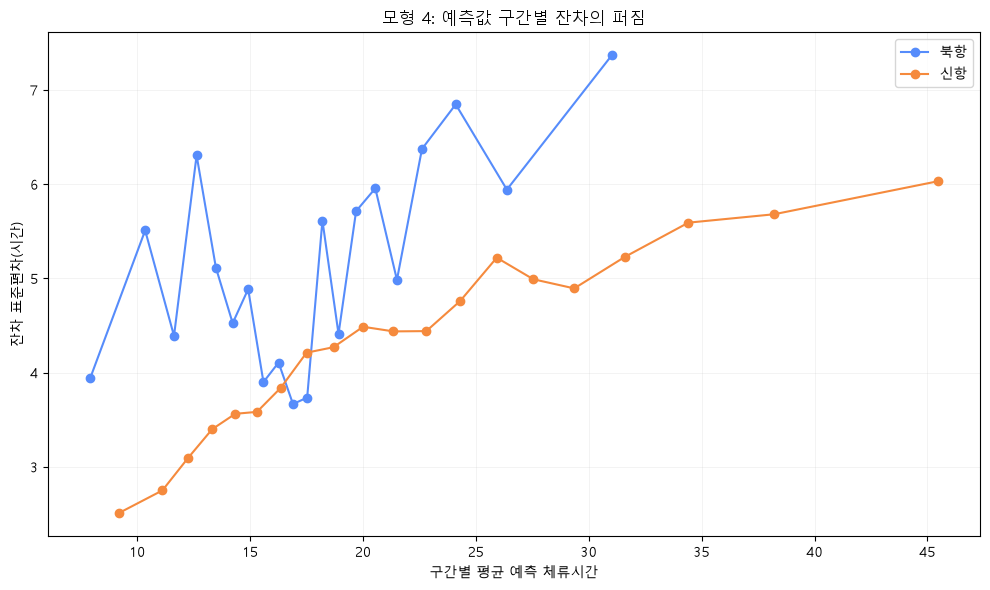


등분산성 검정


C:\WORK\stay_multiregression\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


검정,LM 통계량,p값,5% 기준 판단
BP 검정(Koenker),1307.170,<0.001,등분산성 기각
White 검정,5857.419,<0.001,등분산성 기각


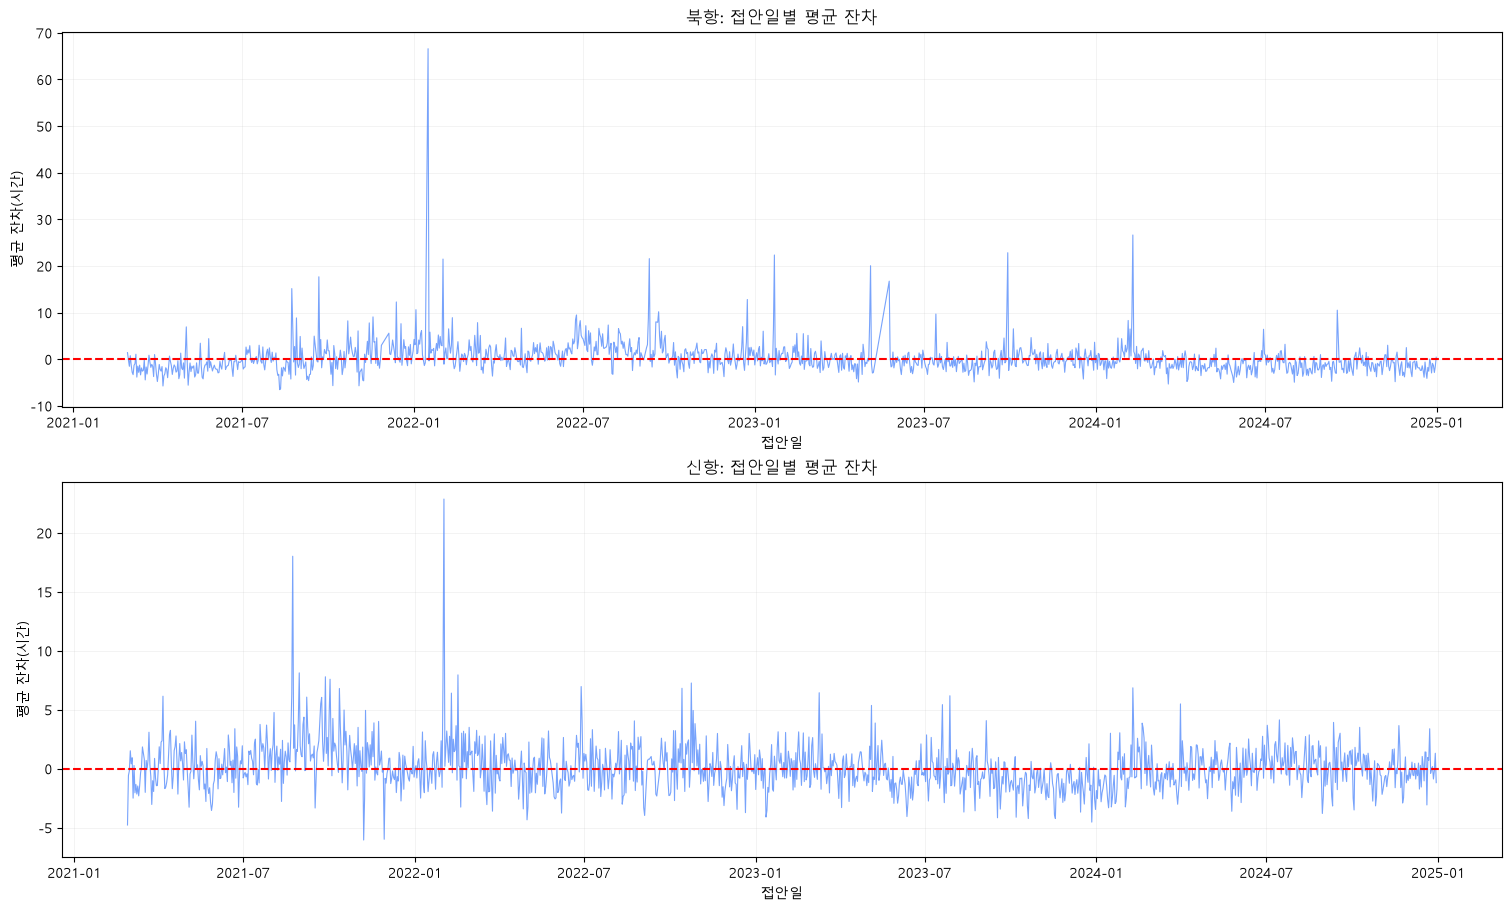


항만구분별 잔차 요약


,표본수,평균잔차,잔차표준편차
항만구분,,,
북항,"16,404",0.000,5.275
신항,"15,610",0.000,4.494



터미널별 잔차 요약


,표본수,평균잔차,잔차표준편차
터미널,,,
BNCT,"3,372",2.568,4.471
BPTC_G,"5,873",-1.041,6.290
BPT_S,"10,531",0.581,4.510
HPNT,"2,817",-0.611,4.444
PNC,"6,405",-1.239,3.612
PNIT,"3,016",0.331,4.996



특보유무별 잔차 요약


,표본수,평균잔차,잔차표준편차
특보유무,,,
0,"27,645",0.000,4.676
1,"4,369",0.000,6.187



선박명별 잔차 요약


,표본수,평균잔차,잔차표준편차
선박명,,,
HEUNG-A ULSAN,376,-0.543,3.727
GLOBAL NUBIRA,331,-0.194,4.222
MAGNA,326,-1.682,2.113
HEUNG-A TOKYO,255,0.323,4.327
PACIFIC BUSAN,240,-0.725,3.325
HAKATA VOYAGER,226,-0.238,3.915
PACIFIC SINGAPORE,207,-0.337,3.713
OSAKA VOYAGER,206,-0.701,6.368
PACIFIC TIANJIN,201,-0.672,3.959


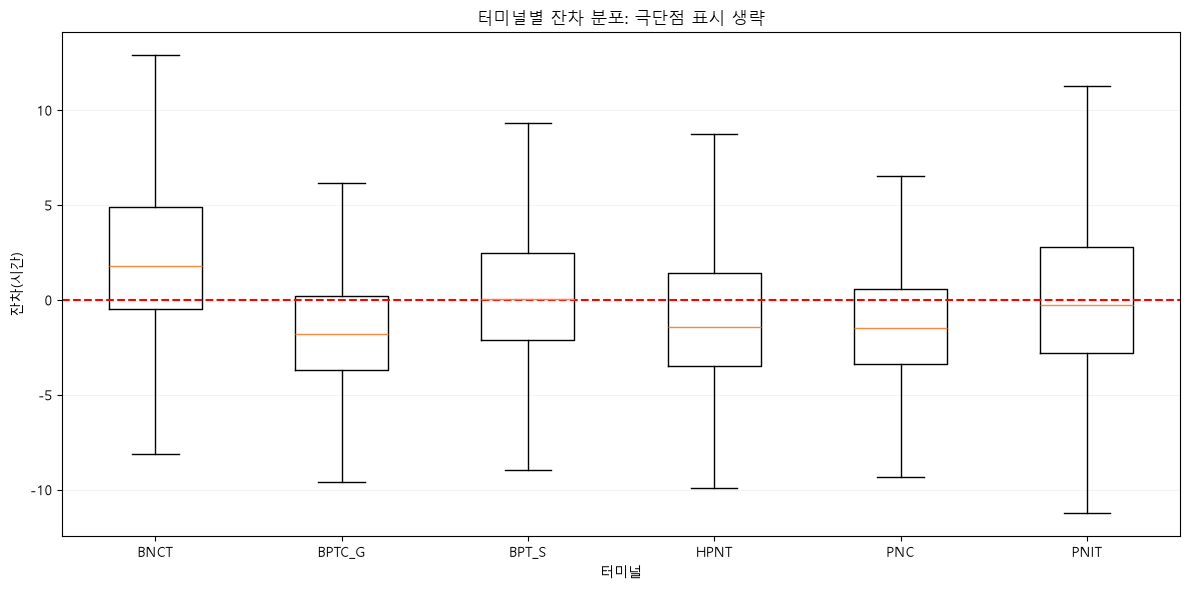

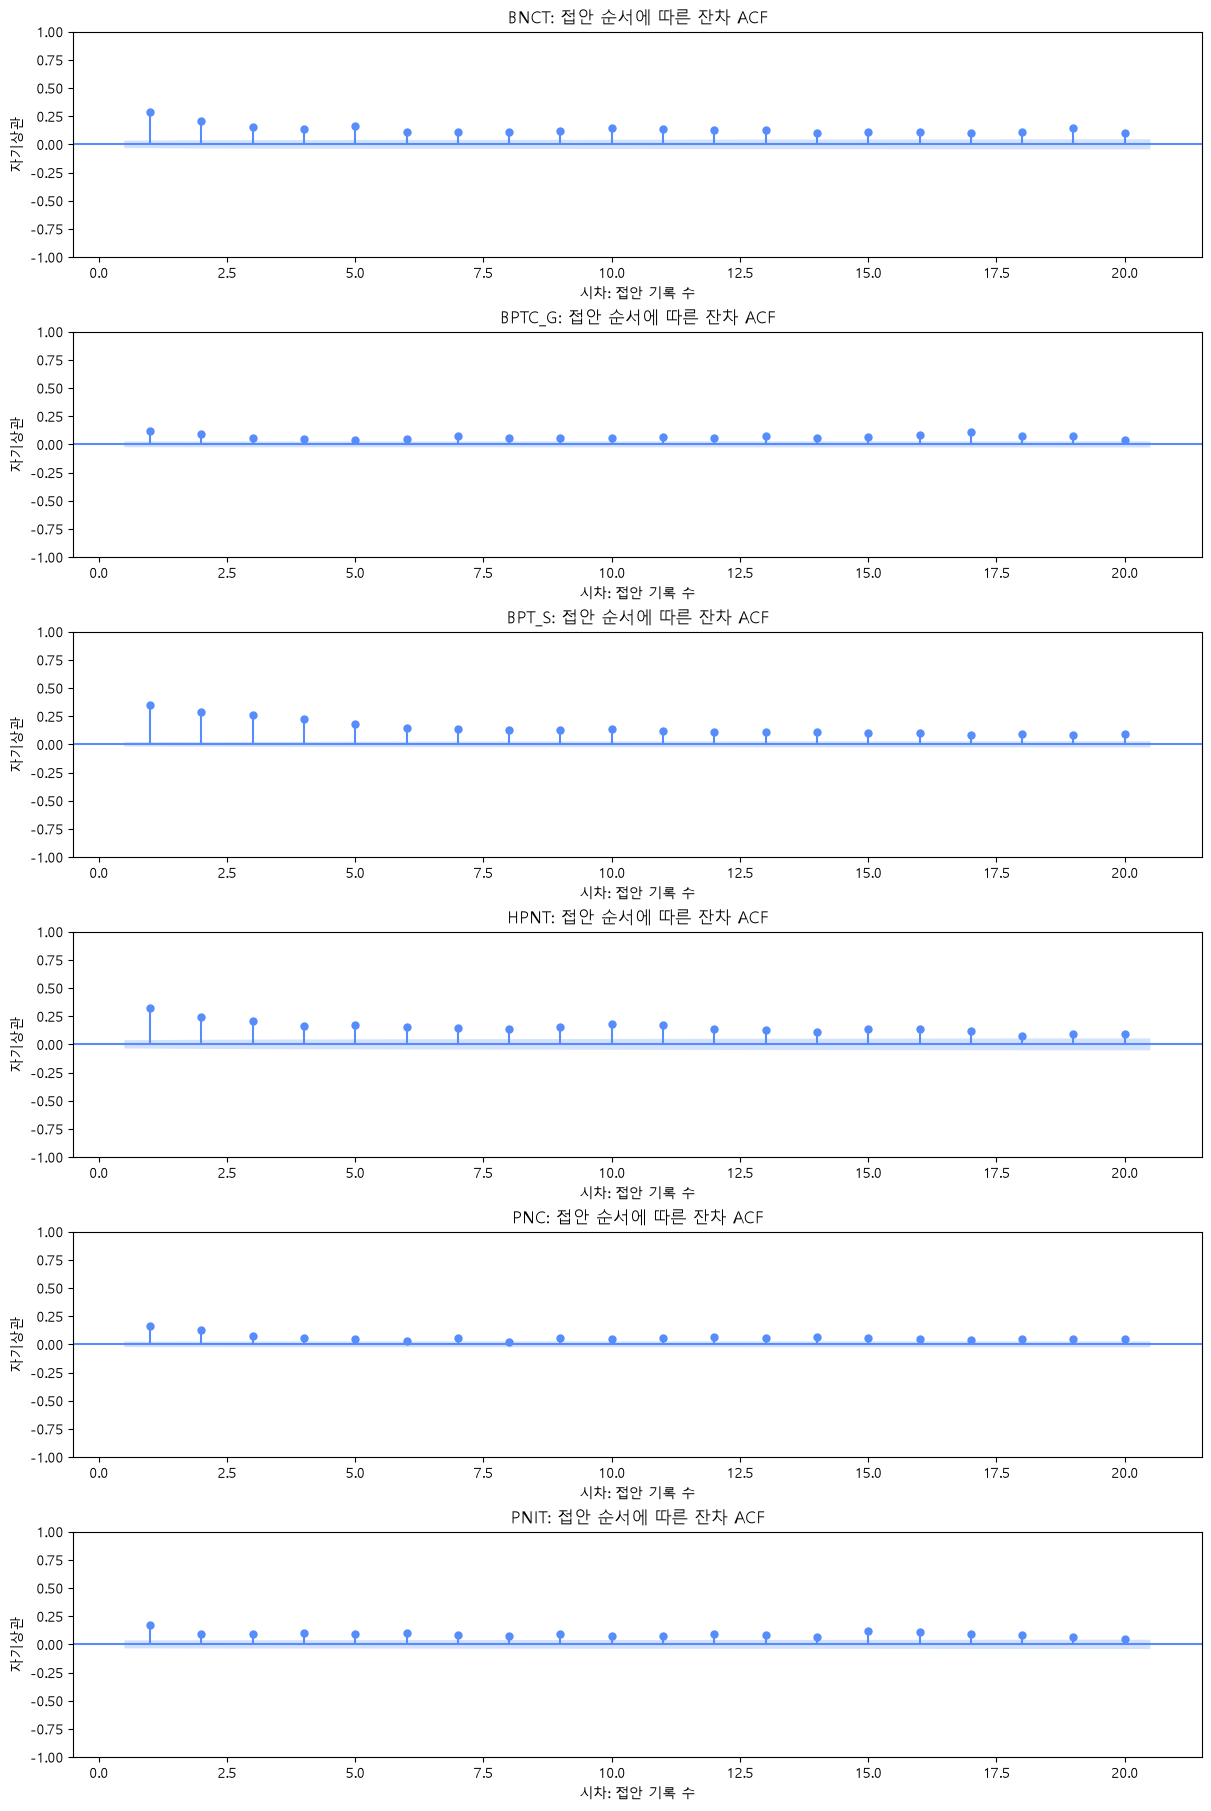


터미널별 자기상관 탐색


터미널,표본 수,DW,시차(접안 기록 수),Ljung–Box 통계량,p값
BNCT,3372,1.065,1,286.914,<0.001
BNCT,3372,1.065,5,670.862,<0.001
BNCT,3372,1.065,10,912.902,<0.001
BNCT,3372,1.065,20,1378.590,<0.001
BPTC_G,5873,1.717,1,81.699,<0.001
BPTC_G,5873,1.717,5,173.349,<0.001
BPTC_G,5873,1.717,10,279.819,<0.001
BPTC_G,5873,1.717,20,578.515,<0.001
BPT_S,10531,1.275,1,1303.791,<0.001
BPT_S,10531,1.275,5,3759.972,<0.001


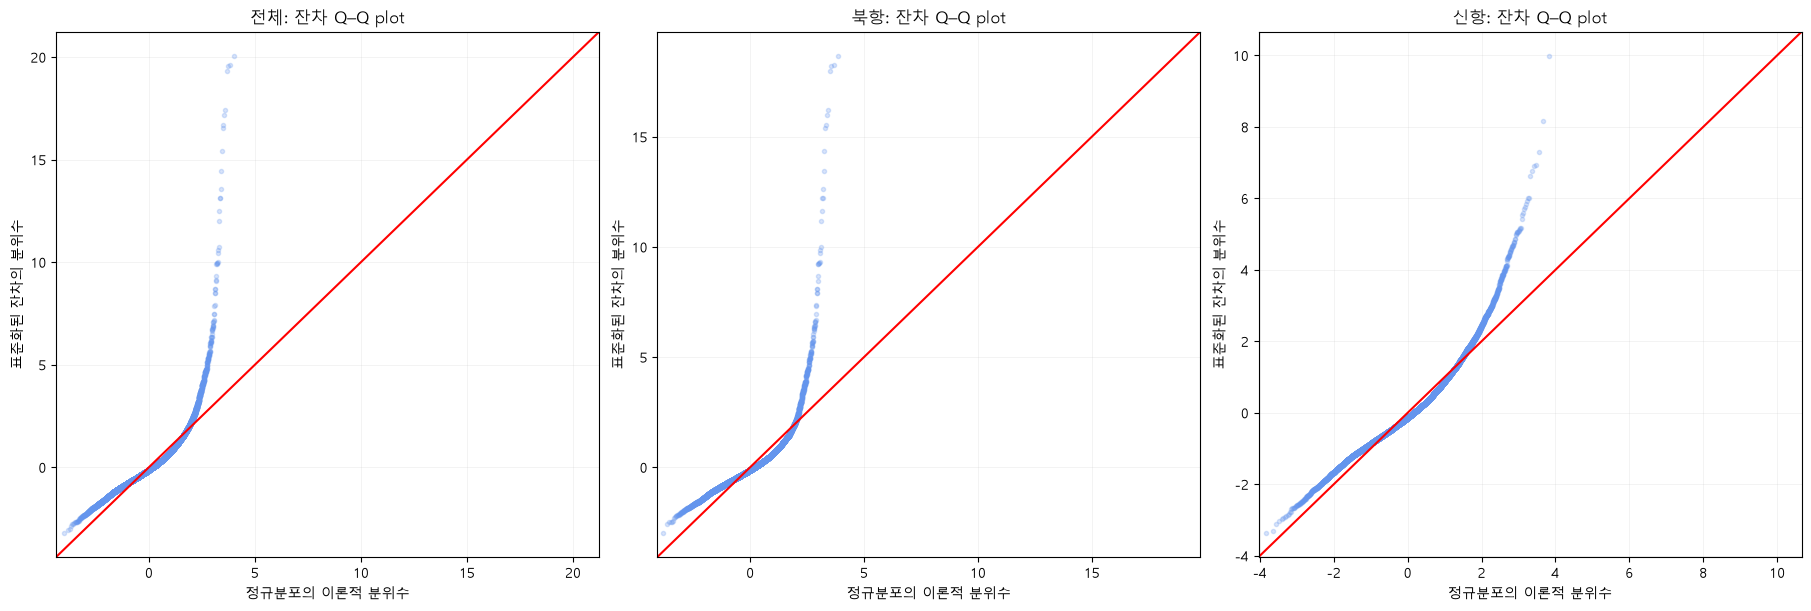

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from IPython.display import display
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    het_white,
    acorr_ljungbox,
)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ==================================================
# 1. 모형 4에서 실제 사용한 행의 정보와 잔차 가져오기
# ==================================================

used_index = model_4.model.data.row_labels

diagnosis = df.loc[used_index].copy()

# to_numpy(): 원래 행 순서대로 값을 넣기 위해 사용
diagnosis["예측값"] = np.asarray(model_4.fittedvalues)
diagnosis["잔차"] = np.asarray(model_4.resid)

diagnosis["접안일시"] = pd.to_datetime(
    diagnosis["접안일시"],
    errors="raise",
)

print(f"모형 4 진단 표본 수: {len(diagnosis):,}")

# ==================================================
# 2. 잔차–예측값, 잔차–각 X 그래프
# ==================================================

# 상호작용항 자체보다 원래 변수별 잔차 패턴을 먼저 확인
continuous_vars = [
    "총톤수",
    "총작업량",
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
]


def draw_residual_pattern(ax, x_col):
    """
    산점도: 실제 잔차
    빨간 선: X를 최대 20개 구간으로 나눈 구간별 평균 잔차
    항만별로 나누어 반대 방향의 패턴이 상쇄되는지 확인
    """
    for port, color in [
        ("북항", "royalblue"),
        ("신항", "darkorange"),
    ]:
        part = diagnosis[diagnosis["항만구분"] == port]

        if part.empty:
            continue

        ax.scatter(
            part[x_col],
            part["잔차"],
            s=8,
            alpha=0.08,
            color=color,
            edgecolors="none",
        )

        bins = pd.qcut(
            part[x_col],
            q=20,
            duplicates="drop",
        )

        trend = (
            part.groupby(bins, observed=True)
            .agg(
                x=(x_col, "mean"),
                평균잔차=("잔차", "mean"),
            )
        )

        ax.plot(
            trend["x"],
            trend["평균잔차"],
            color=color,
            linewidth=2,
            marker="o",
            markersize=3,
            label=f"{port}: 구간별 평균 잔차",
        )

    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel(x_col)
    ax.set_ylabel("잔차(시간)")
    ax.set_title(f"{x_col}와 잔차")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


# 잔차–예측값
fig, ax = plt.subplots(figsize=(11, 6))
draw_residual_pattern(ax, "예측값")
plt.tight_layout()
plt.show()

# 잔차–각 연속형 독립변수
fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20),
    layout="constrained",
)

for ax, col in zip(axes.flatten(), continuous_vars):
    draw_residual_pattern(ax, col)

fig.suptitle("모형 4: 항만별 독립변수와 잔차 패턴", fontsize=16)
plt.show()

# ==================================================
# 3. 등분산성: 예측값 구간별 잔차 표준편차
# ==================================================

fig, ax = plt.subplots(figsize=(10, 6))

for port in ["북항", "신항"]:
    part = diagnosis[diagnosis["항만구분"] == port]

    bins = pd.qcut(
        part["예측값"],
        q=20,
        duplicates="drop",
    )

    spread = (
        part.groupby(bins, observed=True)
        .agg(
            평균예측값=("예측값", "mean"),
            잔차표준편차=("잔차", "std"),
            표본수=("잔차", "size"),
        )
    )

    ax.plot(
        spread["평균예측값"],
        spread["잔차표준편차"],
        marker="o",
        label=port,
    )

ax.set_title("모형 4: 예측값 구간별 잔차의 퍼짐")
ax.set_xlabel("구간별 평균 예측 체류시간")
ax.set_ylabel("잔차 표준편차(시간)")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

# ==================================================
# 4. 등분산성: BP·White 검정
# ==================================================

# 수치 크기 차이로 인한 계산 문제를 줄이기 위해
# 검정용 설명변수만 표준화한다.
# 기존 model_4의 회귀계수와 예측값은 변경하지 않는다.
test_X = pd.DataFrame(
    model_4.model.exog,
    columns=model_4.model.exog_names,
).drop(columns="const")

test_X = (test_X - test_X.mean()) / test_X.std(ddof=0)
test_X = sm.add_constant(test_X, has_constant="add")

residual = diagnosis["잔차"].to_numpy()

bp = het_breuschpagan(
    residual,
    test_X.to_numpy(),
    robust=True,  # Koenker 방식
)

white = het_white(
    residual,
    test_X.to_numpy(),
)

hetero_result = pd.DataFrame({
    "검정": ["BP 검정(Koenker)", "White 검정"],
    "LM 통계량": [bp[0], white[0]],
    "p값": [bp[1], white[1]],
})

hetero_result["5% 기준 판단"] = [
    "등분산성 기각" if p < 0.05 else "등분산성 기각 못함"
    for p in hetero_result["p값"]
]

print("\n등분산성 검정")
display(
    hetero_result.style
    .format({
        "LM 통계량": "{:.3f}",
        "p값": lambda p: "<0.001" if p < 0.001 else f"{p:.3f}",
    })
    .hide(axis="index")
)

# ==================================================
# 5. 시간적 패턴: 항만별 일평균 잔차
# ==================================================

diagnosis["접안일"] = diagnosis["접안일시"].dt.floor("D")

daily = (
    diagnosis.groupby(["항만구분", "접안일"])["잔차"]
    .agg(["mean", "std", "size"])
    .reset_index()
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    layout="constrained",
)

for ax, port in zip(axes, ["북항", "신항"]):
    part = daily[daily["항만구분"] == port]

    ax.plot(
        part["접안일"],
        part["mean"],
        linewidth=0.8,
        alpha=0.8,
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{port}: 접안일별 평균 잔차")
    ax.set_xlabel("접안일")
    ax.set_ylabel("평균 잔차(시간)")
    ax.grid(alpha=0.2)

plt.show()

# ==================================================
# 6. 집단별 패턴: 항만·터미널·특보유무·선박
# ==================================================

for group_col in ["항만구분", "터미널", "특보유무", "선박명"]:
    group_summary = (
        diagnosis.groupby(group_col)["잔차"]
        .agg(
            표본수="size",
            평균잔차="mean",
            잔차표준편차="std",
        )
    )

    # 선박은 반복 관측이 있는 선박 중 표본이 많은 20개만 표시
    if group_col == "선박명":
        group_summary = (
            group_summary[group_summary["표본수"] >= 2]
            .sort_values("표본수", ascending=False)
            .head(20)
        )

    print(f"\n{group_col}별 잔차 요약")
    display(
        group_summary.style.format({
            "표본수": "{:,.0f}",
            "평균잔차": "{:.3f}",
            "잔차표준편차": "{:.3f}",
        })
    )

# 터미널별 잔차 분포
terminal_groups = list(
    diagnosis.groupby("터미널", sort=True)
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    [part["잔차"].to_numpy() for _, part in terminal_groups],
    showfliers=False,
)

ax.set_xticks(
    range(1, len(terminal_groups) + 1),
    [str(name) for name, _ in terminal_groups],
)

ax.axhline(0, color="red", linestyle="--")
ax.set_title("터미널별 잔차 분포: 극단점 표시 생략")
ax.set_xlabel("터미널")
ax.set_ylabel("잔차(시간)")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# ==================================================
# 7. 자기상관: 터미널별 접안 순서 기준
# ==================================================

# 시차 1 = 같은 터미널에서 다음 접안 기록
# 시차 1시간 또는 1일이라는 뜻은 아님
autocorr_records = []

fig, axes = plt.subplots(
    len(terminal_groups),
    1,
    figsize=(12, 3 * len(terminal_groups)),
    squeeze=False,
    layout="constrained",
)

for ax, (terminal, part) in zip(
        axes.flatten(),
        terminal_groups,
):
    ordered = part.sort_values(
        "접안일시",
        kind="stable",
    )

    r = ordered["잔차"].to_numpy()

    if len(r) < 20:
        ax.set_title(f"{terminal}: 자기상관 점검 표본 부족")
        continue

    # 최대 시차는 표본 수를 고려해 제한
    max_lag = min(20, len(r) // 5)
    test_lags = [
        lag for lag in [1, 5, 10, 20]
        if lag <= max_lag
    ]

    lb = acorr_ljungbox(
        r,
        lags=test_lags,
        return_df=True,
    )

    dw = durbin_watson(r)

    for lag, row in lb.iterrows():
        autocorr_records.append({
            "터미널": terminal,
            "표본 수": len(r),
            "DW": dw,
            "시차(접안 기록 수)": lag,
            "Ljung–Box 통계량": row["lb_stat"],
            "p값": row["lb_pvalue"],
        })

    plot_acf(
        r,
        lags=max_lag,
        zero=False,
        fft=True,
        ax=ax,
    )

    ax.set_title(f"{terminal}: 접안 순서에 따른 잔차 ACF")
    ax.set_xlabel("시차: 접안 기록 수")
    ax.set_ylabel("자기상관")

plt.show()

autocorr_result = pd.DataFrame(autocorr_records)

print("\n터미널별 자기상관 탐색")
display(
    autocorr_result.style
    .format({
        "DW": "{:.3f}",
        "Ljung–Box 통계량": "{:.3f}",
        "p값": lambda p: "<0.001" if p < 0.001 else f"{p:.3f}",
    })
    .hide(axis="index")
)

# ==================================================
# 8. 잔차 정규성: 전체 및 항만별 Q–Q plot
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    layout="constrained",
)

qq_groups = [
    ("전체", diagnosis),
    ("북항", diagnosis[diagnosis["항만구분"] == "북항"]),
    ("신항", diagnosis[diagnosis["항만구분"] == "신항"]),
]

for ax, (name, part) in zip(axes, qq_groups):
    sm.qqplot(
        part["잔차"].to_numpy(),
        fit=True,
        line="45",
        ax=ax,
        markerfacecolor="cornflowerblue",
        markeredgecolor="cornflowerblue",
        alpha=0.25,
        markersize=3,
    )

    ax.set_title(f"{name}: 잔차 Q–Q plot")
    ax.set_xlabel("정규분포의 이론적 분위수")
    ax.set_ylabel("표준화된 잔차의 분위수")
    ax.grid(alpha=0.2)

plt.show()